<h1>Feature Engineering on the flight dataset<h1>

In [15]:
import numpy as np
import pandas as pd

original = pd.read_csv("data.csv")
compition = pd.read_csv('train.csv').drop(columns = ["id"])
test  = pd.read_csv('test.csv')

train_df = pd.concat([original,compition])
test_df = pd.read_csv("test.csv")

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["satisfaction", "id"], errors="ignore")
y = df["satisfaction"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (663612, 21)
X_val: (165903, 21)
y_train: (663612,)
y_val: (165903,)


In [17]:
df

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,Female,Loyal Customer,57,Business travel,Eco,612,2,1,1,1,...,3,2,2,2,2,2,4,0,0.0,False
699631,Female,disloyal Customer,30,Business travel,Eco,862,2,2,2,3,...,4,4,2,5,4,2,4,24,34.0,False
699632,Male,Loyal Customer,49,Business travel,Business,3148,5,5,5,5,...,4,5,5,5,5,5,5,0,0.0,True
699633,Female,Loyal Customer,61,Business travel,Eco,679,5,2,2,2,...,4,5,4,5,5,5,1,0,0.0,True


<h1>Feature Engineering

In [18]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Separate target and features
y = train_df["satisfaction"].copy()

X = train_df.drop(
    columns=["satisfaction", "id"],
    errors="ignore"
).copy()

# Prepare competition test features
test_ids = test_df["id"].copy()

X_submission = test_df.drop(
    columns=["id", "satisfaction"],
    errors="ignore"
).copy()

# Ensure training and test features have identical columns and order
X_submission = X_submission.reindex(columns=X.columns)

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

num_cols = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)

# Split the training data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_submission.shape)

Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Numerical columns: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
Training shape: (663612, 21)
Validation shape: (165903, 21)
Test shape: (299844, 21)


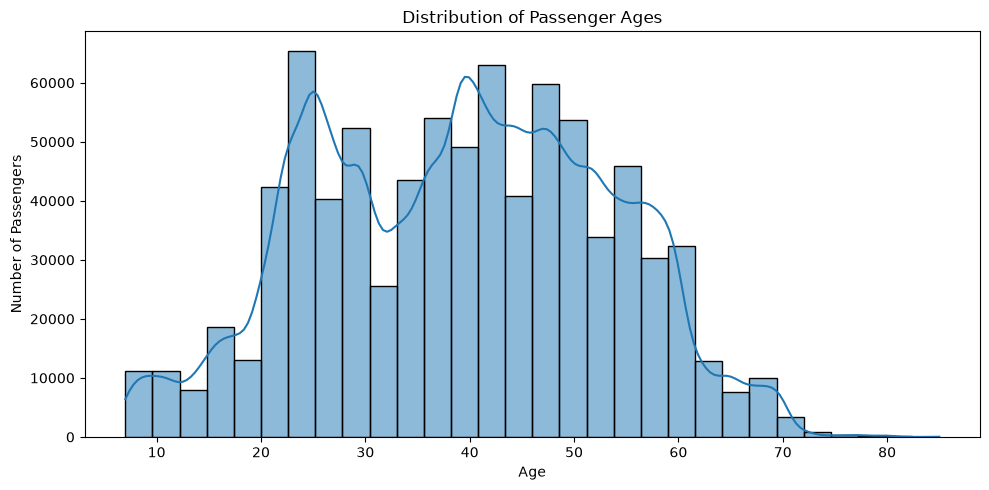

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check age distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd

age_bins = [0, 18, 25, 35, 45, 55, 65, 100]

age_labels = [
    "0-18",
    "19-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

train_df["AgeGroup"] = pd.cut(
    train_df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print(train_df.groupby(
    "AgeGroup",
    observed=False
)["satisfaction"].value_counts().unstack(fill_value=0))

satisfaction   False   True 
AgeGroup                    
0-18           47384    8267
19-25          78909   34987
26-35         104176   57619
36-45          96849  110056
46-55          71733  106328
56-65          47699   47297
66+            15998    2213


Satisfaction labels: <StringArray>
['false', 'true']
Length: 2, dtype: str
AgeGroup
0-18     0.0
19-25    0.0
26-35    0.0
36-45    0.0
46-55    0.0
56-65    0.0
66+      0.0
Name: satisfaction, dtype: float64


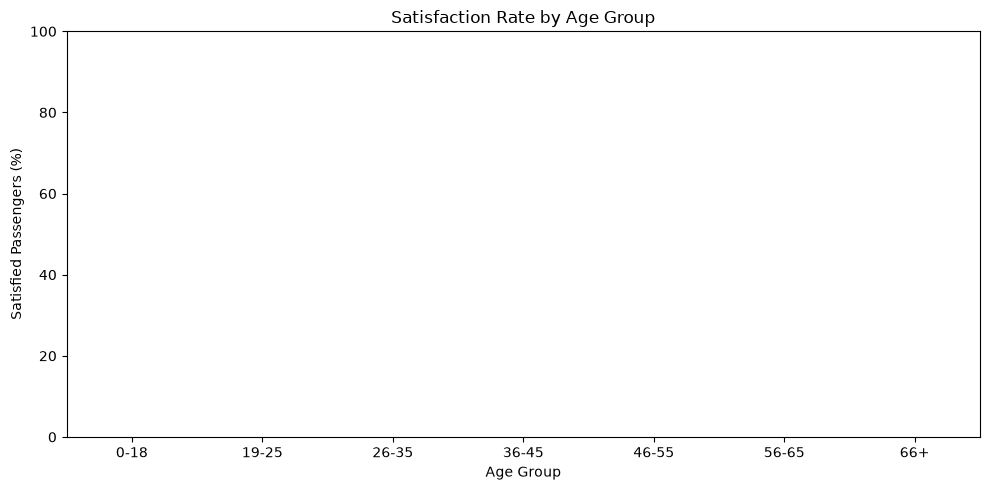

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Normalize target labels
satisfaction = train_df["satisfaction"].astype(str).str.strip().str.lower()

# Check the actual labels
print("Satisfaction labels:", satisfaction.unique())

# Create age groups
bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = ["0-18", "19-25", "26-35", "36-45", "46-55", "56-65", "66+"]

train_df["AgeGroup"] = pd.cut(
    train_df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate the percentage of satisfied passengers in each age group
satisfied_rate = (
    satisfaction.eq("satisfied")
    .groupby(train_df["AgeGroup"], observed=False)
    .mean()
    .mul(100)
)

print(satisfied_rate)

# Visualize
plt.figure(figsize=(10, 5))
sns.barplot(x=satisfied_rate.index, y=satisfied_rate.values)

plt.title("Satisfaction Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Satisfied Passengers (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


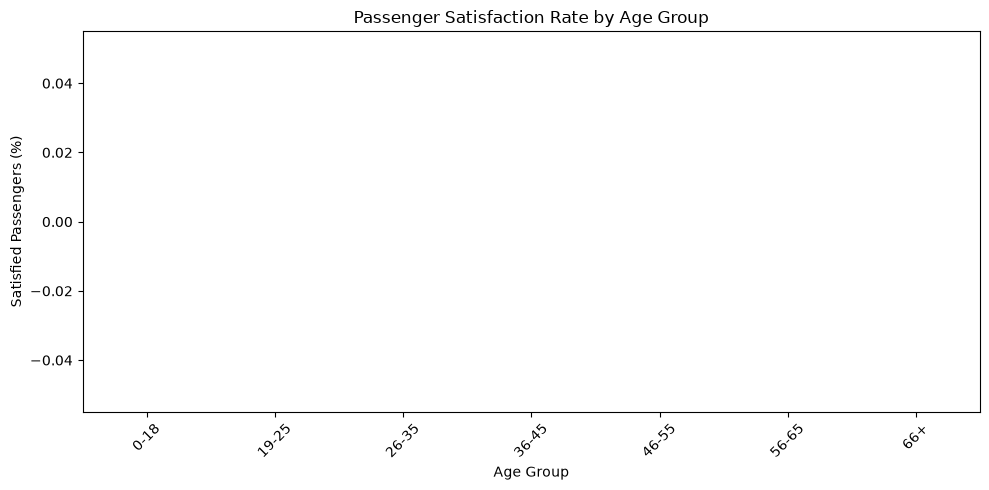

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=satisfaction_rate,
    x="AgeGroup",
    y="SatisfactionRate"
)

plt.title("Passenger Satisfaction Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Satisfied Passengers (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()